# Horizon and baselines: what the recurrent networks and the Transformer buy on the near-wall signal

One experiment across Stages 1–3. Every model sees **the same windows** (300 past values of the streamwise velocity at y index 50 → the next 10 values, stride 10), **the same chronological split** (70 % / 15 % / 15 % of the windows, in time order) and **the same test period**, all built by `CFDTimeSeriesLoader.prepare_forecasting_data` from the processed signal that the extraction notebook writes.

- **Part (a): error against forecast step.** Mean absolute error (MAE) at each of the 10 steps of the output window for SimpleRNN, LSTM, GRU and the Transformer, against persistence and a linear autoregressive model fitted by least squares on the training windows.
- **Part (b): what the extra complexity buys.** Parameters, training time and test error per model, and whether each model beats the linear model by more than its seed spread.

Three seeds (0, 1, 2) per network. Errors are in normalised units (training mean and standard deviation).

# Stage 4 — Horizon and baselines: what the networks buy over a linear model

**Portfolio project: forecasting a turbulent channel-flow signal with recurrent networks and a Transformer.**

Stages 2 and 3 compare their networks with persistence only. Here I put SimpleRNN, GRU, LSTM and the Stage 3 Transformer on exactly the same windows and test period as Stages 2 and 3, all predicting the full 10-step window, with three seeds each, next to persistence and the reference a careful engineer would try first: a linear autoregressive model, each future value a weighted sum of the past values, fitted by ordinary least squares on the training windows in 42 ms. Part (a) gives the error at every forecast step; part (b) sets parameters and training time against test error.

**What it shows.** The linear model's error over the 10 steps is 0.0004 (normalised), 77 to 258 times lower than any network; fitted on only the last 2 values it already reaches 0.035. The recurrent networks (about 0.031) beat persistence (0.103) by far more than their seed spread and do not differ from one another; the Transformer, trained with the Stage 3 settings, does not beat persistence. The signal is sampled every 0.01 time units and is smooth over 10 samples, so a linear extrapolation from the recent past is nearly exact at these horizons.

**How it connects.** It reads `data/utmp_y50_raw_timeseries.h5` (Stage 1) through `cfd_data_tools.py` with the same call as Stages 2 and 3, and copies the Transformer builder of Stage 3 unchanged. The device timings it reads (`device_timing_*.csv`) were measured before any training, one training step of each network on the CPU and on the Apple GPU.

**About the outputs.** The outputs below come from my single run (Apple M3 Max, 2026-10-13, 20.6 minutes). Afterwards I changed only text for this repository: this cell and the paths cell, and the path lines (data from `../data/`, tables and figures to `../results/04_horizon_and_baselines/`, seed-0 models to `../models/04_horizon_and_baselines/`). The part (b) figure uses a linear error axis on which the linear model sits at the bottom edge; the table beneath it gives the numbers.

In [ ]:
# Paths in the repository layout (run this notebook from notebooks/)
from pathlib import Path
DATA_FILE = Path("../data/utmp_y50_raw_timeseries.h5")          # written by Stage 1
RESULTS = Path("../results/04_horizon_and_baselines")             # also holds the device timings read below
MODELS = Path("../models/04_horizon_and_baselines")
for p in (RESULTS, MODELS): p.mkdir(parents=True, exist_ok=True)
print("processed signal present:", DATA_FILE.exists(), "| device timings present:", (RESULTS / "device_timing_cpu.csv").exists())

In [1]:
import json, time, pathlib
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from cfd_data_tools import CFDTimeSeriesLoader

# Device per network from the step timing (../results/04_horizon_and_baselines/device_timing_cpu.csv, device_timing_gpu.csv):
# median of 30 training steps inside model.fit after 10 warm-up steps, batch 64, window 300.
timing = pd.concat([pd.read_csv("../results/04_horizon_and_baselines/device_timing_cpu.csv"), pd.read_csv("../results/04_horizon_and_baselines/device_timing_gpu.csv")])
timing_tab = timing.pivot(index="network", columns="device", values="median_ms")
print(timing_tab.round(2))
NET_DEVICE = {"SimpleRNN": "/CPU:0", "GRU": "/GPU:0", "LSTM": "/GPU:0", "Simple Transformer": "/GPU:0"}
for k, v in NET_DEVICE.items():
    faster = "/CPU:0" if timing_tab.loc[k, "cpu"] < timing_tab.loc[k, "gpu"] else "/GPU:0"
    assert faster == v, (k, faster, v)
print("Device per network:", NET_DEVICE)
RES = pathlib.Path("../results/04_horizon_and_baselines"); RES.mkdir(parents=True, exist_ok=True)
MOD = pathlib.Path("../models/04_horizon_and_baselines"); MOD.mkdir(parents=True, exist_ok=True)

device                 cpu       gpu
network                             
Dense baseline        0.35      5.97
GRU                  35.49     17.73
LSTM                 23.30     18.21
Simple Transformer  126.53     53.15
SimpleRNN             8.61  15532.45
Stacked GRU          81.06     25.99
Device per network: {'SimpleRNN': '/CPU:0', 'GRU': '/GPU:0', 'LSTM': '/GPU:0', 'Simple Transformer': '/GPU:0'}


In [2]:
# The same windows, split and normalisation as Stages 2 and 3
loader = CFDTimeSeriesLoader(processed_dir="../data", y_index=50, variable="utmp")
loader.load_processed_h5("../data/utmp_y50_raw_timeseries.h5")
data = loader.prepare_forecasting_data(input_window=300, output_window=10, stride=10, batch_size=64)
Xtr, ytr = data["X_train"].astype("float32"), np.asarray(data["y_train"], dtype="float32")
Xva, yva = data["X_val"].astype("float32"), np.asarray(data["y_val"], dtype="float32")
Xte, yte = data["X_test"].astype("float32"), np.asarray(data["y_test"], dtype="float32")
print("train", Xtr.shape, ytr.shape, "| val", Xva.shape, "| test", Xte.shape)
STEPS = np.arange(1, 11)

Processed HDF5 loaded from:
../data/utmp_y50_raw_timeseries.h5

Loaded arrays:
all_signal: (106000,)
all_timev: (106000,)
all_file_indices: (106000,)
Forecasting windows created:
X: (7419, 300, 1)
y: (7419, 10)
Normalization statistics:
signal_mean: 0.9274324
signal_std: 0.10147347
train (5193, 300, 1) (5193, 10) | val (1112, 300, 1) | test (1114, 300, 1)


2026-10-13 15:33:22.167126: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3 Max
2026-10-13 15:33:22.167151: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-10-13 15:33:22.167156: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1791920002.167166 49142139 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1791920002.167183 49142139 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## The two references

**Persistence**: every future value equals the last input value. **Linear autoregressive model**: each of the 10 future values is a weighted sum of the 300 past values plus a constant, `y = [x, 1] W`, with `W` (301 × 10) fitted by ordinary least squares on the training windows only. It has no hyperparameter, so the validation windows are not used.

In [3]:
pers_te = np.repeat(Xte[:, -1, :], 10, axis=1)
pers_steps = np.mean(np.abs(yte - pers_te), axis=0)

t0 = time.perf_counter()
A = np.hstack([Xtr[:, :, 0], np.ones((len(Xtr), 1), dtype="float32")]).astype("float64")
W, *_ = np.linalg.lstsq(A, ytr.astype("float64"), rcond=None)
lin_fit_s = time.perf_counter() - t0
lin_te = np.hstack([Xte[:, :, 0], np.ones((len(Xte), 1))]) @ W
lin_steps = np.mean(np.abs(yte - lin_te), axis=0)
lin_va = np.mean(np.abs(yva - np.hstack([Xva[:, :, 0], np.ones((len(Xva), 1))]) @ W))
print(f"Persistence test MAE {pers_steps.mean():.4f} | linear AR test MAE {lin_steps.mean():.4f} (validation {lin_va:.4f}), "
      f"{W.size} coefficients, fitted in {lin_fit_s * 1000:.0f} ms")
print("Condition number of the training design matrix:", f"{np.linalg.cond(A):.3g}")

Persistence test MAE 0.1028 | linear AR test MAE 0.0004 (validation 0.0004), 3010 coefficients, fitted in 42 ms
Condition number of the training design matrix: 2.34e+07


**How many past values does the linear model need?** The same least-squares fit on only the last L values of each window (L = 1 reproduces persistence up to a fitted gain and offset). Fitted on the training windows, scored on the test windows.

In [4]:
lag_rows = []
for L in (1, 2, 3, 5, 10, 30, 100, 300):
    AL = np.hstack([Xtr[:, -L:, 0], np.ones((len(Xtr), 1), dtype="float32")]).astype("float64")
    WL, *_ = np.linalg.lstsq(AL, ytr.astype("float64"), rcond=None)
    pL = np.hstack([Xte[:, -L:, 0], np.ones((len(Xte), 1))]) @ WL
    e = np.mean(np.abs(yte - pL), axis=0)
    lag_rows.append(dict(lags=L, coefficients=WL.size, test_mae=float(e.mean()), mae_step1=float(e[0]), mae_step10=float(e[-1])))
lags = pd.DataFrame(lag_rows); lags.to_csv(RES / "a_linear_lags.csv", index=False)
print(lags.to_string(index=False, float_format=lambda v: f"{v:.5f}"))

 lags  coefficients  test_mae  mae_step1  mae_step10
    1            20   0.10288    0.01897     0.18460
    2            30   0.03548    0.00177     0.08439
    3            40   0.01567    0.00026     0.04533
    5            60   0.00267    0.00001     0.00990
   10           110   0.00131    0.00001     0.00502
   30           310   0.00051    0.00000     0.00199
  100          1010   0.00040    0.00000     0.00155
  300          3010   0.00040    0.00000     0.00156


## The networks

- **SimpleRNN, GRU, LSTM**: hidden size 32 (Stage 2's), then `Dense(10)` so that each predicts the whole 10-value window (Stage 2's own models end in `Dense(1)` and cannot be read step by step). Adam with learning rate 1e-3 (Stage 2's) and gradient clipping at norm 1.
- **Simple Transformer**: Stage 3's `create_simple_transformer` (d_model 32, 4 heads, feed-forward 64, 2 blocks, dropout 0.1, Adam 1e-4 with clipping at norm 1), copied below unchanged from its sections 5.1, 6 and 7.
- **Common training**: mean squared error loss, batch 64, at most 50 epochs, early stopping on the validation loss (patience 8, best weights restored), learning rate halved after 4 epochs without improvement (minimum 1e-6). The seed sets the initial weights, dropout and the training-set shuffle.

In [5]:
# Copied unchanged from Stage 3 (sections 5.1, 6 and 7)

# =========================================================
# 5.1. Positional embedding layer
# =========================================================

class PositionalEmbedding(tf.keras.layers.Layer):
    """
    Adds trainable positional information to the input sequence.

    The Transformer does not process the sequence step by step like an RNN.
    Therefore, we explicitly add information about the position of each time step.
    """

    def __init__(self, sequence_length, d_model):
        super().__init__()
        self.sequence_length = sequence_length
        self.d_model = d_model
        self.position_embedding = tf.keras.layers.Embedding(
            input_dim=sequence_length,
            output_dim=d_model
        )

    def call(self, inputs):
        positions = tf.range(
            start=0,
            limit=tf.shape(inputs)[1],
            delta=1
        )

        positions = self.position_embedding(positions)

        return inputs + positions

    def get_config(self):
        config = super().get_config()
        config.update(
            {
                "sequence_length": self.sequence_length,
                "d_model": self.d_model
            }
        )
        return config


# =========================================================
# 6. Transformer encoder block
# =========================================================

def transformer_encoder_block(
    x,
    d_model=32,
    num_heads=4,
    ff_dim=64,
    dropout_rate=0.1
):
    """
    Simple Transformer encoder block.

    Input shape:
        x → (batch, time, d_model)

    Output shape:
        x → (batch, time, d_model)

    The block contains:
        1. Multi-head self-attention
        2. Residual connection + layer normalization
        3. Feed-forward network
        4. Residual connection + layer normalization
    """

    # -----------------------------------------------------
    # 1. Multi-head self-attention
    # -----------------------------------------------------
    #
    # Self-attention allows each time step to compare itself
    # with all other time steps in the input window.
    #
    # For example, if the input window has 300 time steps,
    # each time step can attend to the other 299 time steps.
    #
    # num_heads controls how many different attention mechanisms
    # are learned in parallel.
    #
    # key_dim is the dimension used by each attention head.
    # Here we choose:
    #
    #     key_dim = d_model // num_heads
    #
    # so that the total attention dimension remains compatible
    # with d_model.
    #
    # The call:
    #
    #     MultiHeadAttention(...)(x, x)
    #
    # means:
    #
    #     query = x
    #     value = x
    #
    # This is self-attention, because the sequence attends to itself.

    attention_output = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )(x, x)

    # -----------------------------------------------------
    # 2. Dropout after attention
    # -----------------------------------------------------
    #
    # Dropout randomly removes part of the attention output
    # during training.
    #
    # This helps reduce overfitting.

    attention_output = tf.keras.layers.Dropout(
        dropout_rate
    )(attention_output)

    # -----------------------------------------------------
    # 3. First residual connection + layer normalization
    # -----------------------------------------------------
    #
    # Residual connection:
    #
    #     x + attention_output
    #
    # This means that the block does not replace x completely.
    # Instead, it adds a correction learned by the attention layer.
    #
    # This makes the network easier to train.
    #
    # LayerNormalization stabilizes the scale of the activations.

    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6
    )(x + attention_output)

    # -----------------------------------------------------
    # 4. Feed-forward network
    # -----------------------------------------------------
    #
    # After attention, each time step is processed by a small
    # dense neural network.
    #
    # This network is applied independently to every time position.
    #
    # First Dense:
    #     expands the representation from d_model to ff_dim.
    #
    # Second Dense:
    #     brings the representation back from ff_dim to d_model.
    #
    # This is necessary because the residual connection later
    # requires both tensors to have the same shape.

    ff_output = tf.keras.layers.Dense(
        ff_dim,
        activation="relu"
    )(x)

    ff_output = tf.keras.layers.Dense(
        d_model
    )(ff_output)

    # -----------------------------------------------------
    # 5. Dropout after feed-forward network
    # -----------------------------------------------------
    #
    # Again, dropout is used to reduce overfitting.

    ff_output = tf.keras.layers.Dropout(
        dropout_rate
    )(ff_output)

    # -----------------------------------------------------
    # 6. Second residual connection + layer normalization
    # -----------------------------------------------------
    #
    # We add the feed-forward correction to the current x:
    #
    #     x + ff_output
    #
    # Then we normalize again.
    #
    # The output keeps the same shape as the input:
    #
    #     (batch, time, d_model)

    x = tf.keras.layers.LayerNormalization(
        epsilon=1e-6
    )(x + ff_output)

    return x

# =========================================================
# 7. Create a simple Transformer forecaster
# =========================================================

def create_simple_transformer(
    window_size,
    output_window,
    d_model=32,
    num_heads=4,
    ff_dim=64,
    num_blocks=2,
    dropout_rate=0.1,
    learning_rate=1e-4
):
    """
    Simple Transformer model for CFD signal forecasting.

    Input:
        (samples, window_size, 1)

    Output:
        (samples, output_window)
    """

    inputs = tf.keras.layers.Input(
        shape=(window_size, 1)
    )

    # Project the scalar signal to d_model features
    x = tf.keras.layers.Dense(
        d_model
    )(inputs)

    # Add positional information
    x = PositionalEmbedding(
        sequence_length=window_size,
        d_model=d_model
    )(x)

    # Transformer encoder blocks
    for _ in range(num_blocks):
        x = transformer_encoder_block(
            x,
            d_model=d_model,
            num_heads=num_heads,
            ff_dim=ff_dim,
            dropout_rate=dropout_rate
        )

    # Last token: information close to the prediction time
    last_token = tf.keras.layers.Lambda(
        lambda z: z[:, -1, :]
    )(x)

    # Global summary: information from the full input window
    global_summary = tf.keras.layers.GlobalAveragePooling1D()(x)

    # Combine local and global information
    x = tf.keras.layers.Concatenate()(
        [last_token, global_summary]
    )

    x = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(
        dropout_rate
    )(x)

    outputs = tf.keras.layers.Dense(
        output_window
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="Simple_Transformer_Forecaster"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate,
            clipnorm=1.0
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


In [6]:
def build(name):
    if name == "Simple Transformer":
        return create_simple_transformer(window_size=300, output_window=10, d_model=32, num_heads=4, ff_dim=64,
                                         num_blocks=2, dropout_rate=0.1, learning_rate=1e-4)
    cell = {"SimpleRNN": tf.keras.layers.SimpleRNN, "GRU": tf.keras.layers.GRU, "LSTM": tf.keras.layers.LSTM}[name]
    m = tf.keras.Sequential([tf.keras.layers.Input(shape=(300, 1)), cell(32), tf.keras.layers.Dense(10)], name=name)
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="mse", metrics=["mae"])
    return m

def make_ds(X, y, shuffle, seed):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).cache()
    if shuffle: ds = ds.shuffle(len(X), seed=seed)
    return ds.batch(64).prefetch(tf.data.AUTOTUNE)

MODELS = ("SimpleRNN", "GRU", "LSTM", "Simple Transformer")
run_rows, step_rows = [], []

def run_seed(seed):
    for name in MODELS:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        with tf.device(NET_DEVICE[name]):
            m = build(name)
            t0 = time.perf_counter()
            h = m.fit(make_ds(Xtr, ytr, True, seed), validation_data=make_ds(Xva, yva, False, seed), epochs=50, verbose=0,
                      callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
                                 tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)])
            train_s = time.perf_counter() - t0
            p = m.predict(Xte, verbose=0, batch_size=256)
        steps = np.mean(np.abs(yte - p), axis=0)
        run_rows.append(dict(model=name, seed=seed, device=NET_DEVICE[name], params=m.count_params(), epochs=len(h.history["loss"]),
                             best_epoch=int(np.argmin(h.history["val_loss"])) + 1, train_s=round(train_s, 1),
                             s_per_epoch=round(train_s / len(h.history["loss"]), 2), test_mae=float(steps.mean())))
        step_rows.extend(dict(model=name, seed=seed, step=int(k), mae=float(v)) for k, v in zip(STEPS, steps))
        if seed == 0:
            m.save(MOD / f"{name.replace(' ', '_')}_seed0.keras")
        print(run_rows[-1], flush=True)

In [7]:
run_seed(0)  # seed 0

{'model': 'SimpleRNN', 'seed': 0, 'device': '/CPU:0', 'params': 1418, 'epochs': 43, 'best_epoch': 35, 'train_s': 37.7, 's_per_epoch': 0.88, 'test_mae': 0.033528417348861694}


2026-10-13 15:34:00.605943: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


{'model': 'GRU', 'seed': 0, 'device': '/GPU:0', 'params': 3690, 'epochs': 46, 'best_epoch': 38, 'train_s': 78.8, 's_per_epoch': 1.71, 'test_mae': 0.03162779659032822}


{'model': 'LSTM', 'seed': 0, 'device': '/GPU:0', 'params': 4682, 'epochs': 29, 'best_epoch': 21, 'train_s': 50.0, 's_per_epoch': 1.72, 'test_mae': 0.04584776237607002}


{'model': 'Simple Transformer', 'seed': 0, 'device': '/GPU:0', 'params': 31562, 'epochs': 50, 'best_epoch': 50, 'train_s': 210.0, 's_per_epoch': 4.2, 'test_mae': 0.10112210363149643}


In [8]:
run_seed(1)  # seed 1

{'model': 'SimpleRNN', 'seed': 1, 'device': '/CPU:0', 'params': 1418, 'epochs': 50, 'best_epoch': 46, 'train_s': 44.1, 's_per_epoch': 0.88, 'test_mae': 0.029851490631699562}


{'model': 'GRU', 'seed': 1, 'device': '/GPU:0', 'params': 3690, 'epochs': 50, 'best_epoch': 42, 'train_s': 89.6, 's_per_epoch': 1.79, 'test_mae': 0.02877167798578739}


{'model': 'LSTM', 'seed': 1, 'device': '/GPU:0', 'params': 4682, 'epochs': 50, 'best_epoch': 50, 'train_s': 85.3, 's_per_epoch': 1.71, 'test_mae': 0.0255192331969738}


{'model': 'Simple Transformer', 'seed': 1, 'device': '/GPU:0', 'params': 31562, 'epochs': 50, 'best_epoch': 45, 'train_s': 218.0, 's_per_epoch': 4.36, 'test_mae': 0.10634096711874008}


In [9]:
run_seed(2)  # seed 2

{'model': 'SimpleRNN', 'seed': 2, 'device': '/CPU:0', 'params': 1418, 'epochs': 50, 'best_epoch': 50, 'train_s': 44.5, 's_per_epoch': 0.89, 'test_mae': 0.02847316861152649}


{'model': 'GRU', 'seed': 2, 'device': '/GPU:0', 'params': 3690, 'epochs': 46, 'best_epoch': 38, 'train_s': 81.5, 's_per_epoch': 1.77, 'test_mae': 0.031660545617341995}


{'model': 'LSTM', 'seed': 2, 'device': '/GPU:0', 'params': 4682, 'epochs': 39, 'best_epoch': 31, 'train_s': 68.3, 's_per_epoch': 1.75, 'test_mae': 0.034769512712955475}


{'model': 'Simple Transformer', 'seed': 2, 'device': '/GPU:0', 'params': 31562, 'epochs': 50, 'best_epoch': 50, 'train_s': 219.0, 's_per_epoch': 4.38, 'test_mae': 0.10188250243663788}


## Part (a): error against forecast step

Test MAE at each forecast step (networks: mean over seeds 0, 1, 2)
      SimpleRNN     GRU    LSTM  Simple Transformer  persistence  linear_AR
step                                                                       
1        0.0061  0.0076  0.0146              0.0340       0.0190     0.0000
2        0.0082  0.0084  0.0120              0.0471       0.0379     0.0000
3        0.0107  0.0106  0.0146              0.0592       0.0568     0.0000
4        0.0146  0.0151  0.0195              0.0758       0.0756     0.0001
5        0.0192  0.0211  0.0269              0.0924       0.0943     0.0001
6        0.0289  0.0266  0.0296              0.1105       0.1128     0.0002
7        0.0379  0.0378  0.0409              0.1269       0.1311     0.0004
8        0.0478  0.0484  0.0537              0.1446       0.1492     0.0006
9        0.0597  0.0589  0.0642              0.1613       0.1669     0.0010
10       0.0731  0.0725  0.0777              0.1794       0.1844     0.0016


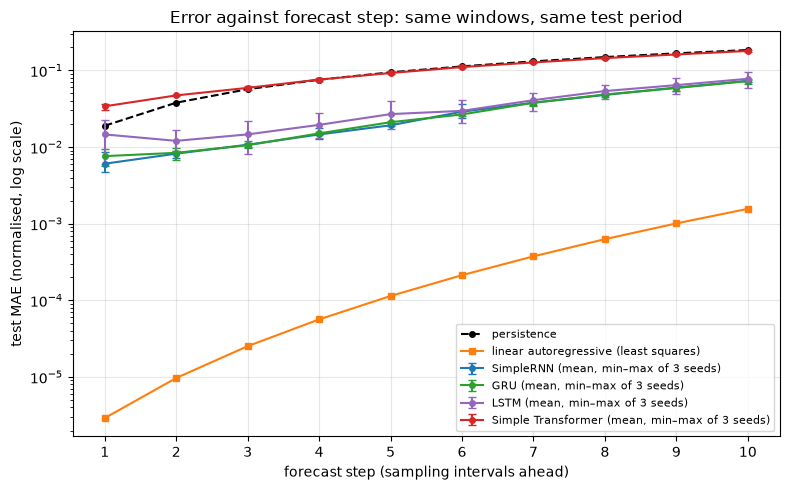

In [10]:
runs = pd.DataFrame(run_rows); steps_df = pd.DataFrame(step_rows)
runs.to_csv(RES / "runs.csv", index=False); steps_df.to_csv(RES / "a_error_by_step_runs.csv", index=False)
a = steps_df.groupby(["model", "step"]).mae.agg(["mean", "std", "min", "max"]).reset_index()
ref = pd.DataFrame(dict(step=STEPS, persistence=pers_steps, linear_AR=lin_steps))
a_wide = a.pivot(index="step", columns="model", values="mean")[list(MODELS)].join(ref.set_index("step"))
a.to_csv(RES / "a_error_by_step_summary.csv", index=False); a_wide.to_csv(RES / "a_error_by_step_table.csv")
print("Test MAE at each forecast step (networks: mean over seeds 0, 1, 2)")
print(a_wide.round(4).to_string())

colors = {"SimpleRNN": "#1f77b4", "GRU": "#2ca02c", "LSTM": "#9467bd", "Simple Transformer": "#d62728"}
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(STEPS, pers_steps, "k--o", ms=4, label="persistence")
ax.plot(STEPS, lin_steps, "-s", color="#ff7f0e", ms=4, label="linear autoregressive (least squares)")
for name in MODELS:
    r = a[a.model == name]
    ax.errorbar(r.step, r["mean"], yerr=[r["mean"] - r["min"], r["max"] - r["mean"]], marker="o", ms=4, capsize=3, color=colors[name], label=f"{name} (mean, min–max of 3 seeds)")
ax.set_yscale("log"); ax.set_xlabel("forecast step (sampling intervals ahead)"); ax.set_ylabel("test MAE (normalised, log scale)"); ax.set_xticks(STEPS)
ax.set_title("Error against forecast step: same windows, same test period"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RES / "a_error_by_step.png", dpi=130); plt.show()

## Part (b): what the extra complexity buys

A model **beats the linear model** only when all three of its seeds are below the linear model's error **and** its mean improvement is larger than its seed range (maximum minus minimum over the three seeds). The linear model is deterministic, so it has no spread of its own. Training times are wall-clock times on each network's faster device.

                           params       device  epochs_mean  train_s_mean  test_mae_mean  test_mae_std  test_mae_min  test_mae_max  gain_over_linear  seed_range beats_linear beats_persistence
model                                                                                                                                                                                          
SimpleRNN                    1418       /CPU:0      47.6667       42.1000         0.0306        0.0026        0.0285        0.0335           -0.0302      0.0051        False              True
GRU                          3690       /GPU:0      47.3333       83.3000         0.0307        0.0017        0.0288        0.0317           -0.0303      0.0029        False              True
LSTM                         4682       /GPU:0      39.3333       67.8667         0.0354        0.0102        0.0255        0.0458           -0.0350      0.0203        False              True
Simple Transformer          31562       

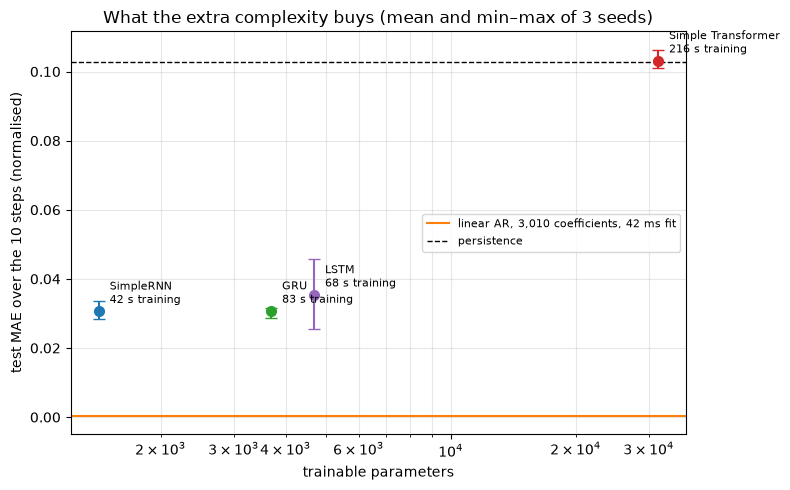

Result (b): SimpleRNN: 0.0306 ± 0.0026, beats linear False; GRU: 0.0307 ± 0.0017, beats linear False; LSTM: 0.0354 ± 0.0102, beats linear False; Simple Transformer: 0.1031 ± 0.0028, beats linear False; linear AR 0.0004; persistence 0.1028


In [11]:
b = runs.groupby("model").agg(params=("params", "first"), device=("device", "first"), epochs_mean=("epochs", "mean"),
                                 train_s_mean=("train_s", "mean"), train_s_min=("train_s", "min"), train_s_max=("train_s", "max"),
                                 test_mae_mean=("test_mae", "mean"), test_mae_std=("test_mae", "std"),
                                 test_mae_min=("test_mae", "min"), test_mae_max=("test_mae", "max")).reindex(list(MODELS))
lin_mae = float(lin_steps.mean()); pers_mae = float(pers_steps.mean())
b["seed_range"] = b.test_mae_max - b.test_mae_min
b["gain_over_linear"] = lin_mae - b.test_mae_mean
b["beats_linear"] = (b.test_mae_max < lin_mae) & (b.gain_over_linear > b.seed_range)
b["beats_persistence"] = (b.test_mae_max < pers_mae) & ((pers_mae - b.test_mae_mean) > b.seed_range)
refs = pd.DataFrame([dict(model="linear AR (least squares)", params=W.size, device="CPU (NumPy)", train_s_mean=round(lin_fit_s, 3), test_mae_mean=lin_mae),
                     dict(model="persistence", params=0, device="—", train_s_mean=0.0, test_mae_mean=pers_mae)]).set_index("model")
b_all = pd.concat([b, refs]); b_all.to_csv(RES / "b_cost_vs_error.csv")
print(b_all[["params", "device", "epochs_mean", "train_s_mean", "test_mae_mean", "test_mae_std", "test_mae_min", "test_mae_max",
             "gain_over_linear", "seed_range", "beats_linear", "beats_persistence"]].round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
for name in MODELS:
    r = b.loc[name]
    ax.errorbar(r.params, r.test_mae_mean, yerr=[[r.test_mae_mean - r.test_mae_min], [r.test_mae_max - r.test_mae_mean]], fmt="o", ms=7, capsize=4, color=colors[name])
    ax.annotate(f"{name}\n{r.train_s_mean:.0f} s training", (r.params, r.test_mae_mean), textcoords="offset points", xytext=(8, 6), fontsize=8)
ax.axhline(lin_mae, color="#ff7f0e", lw=1.5, label=f"linear AR, {W.size:,} coefficients, {lin_fit_s * 1000:.0f} ms fit")
ax.axhline(pers_mae, color="k", ls="--", lw=1, label="persistence")
ax.set_xscale("log"); ax.set_xlabel("trainable parameters"); ax.set_ylabel("test MAE over the 10 steps (normalised)")
ax.set_title("What the extra complexity buys (mean and min–max of 3 seeds)"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8, loc="center right")
fig.tight_layout(); fig.savefig(RES / "b_cost_vs_error.png", dpi=130); plt.show()
print("Result (b): " + "; ".join(f"{k}: {r.test_mae_mean:.4f} ± {r.test_mae_std:.4f}, beats linear {bool(r.beats_linear)}" for k, r in b.iterrows())
      + f"; linear AR {lin_mae:.4f}; persistence {pers_mae:.4f}")